<a href="https://colab.research.google.com/github/Shrishkeshri/Image-pixel-manipulator/blob/main/image_pixel_manipulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🖼️ Image Pixel Manipulator (Synthetic Images)

**Goal:** treat an image as a 3D NumPy array (`height × width × RGB`) and create, crop, recolor, flip and filter images using **only NumPy**. Matplotlib is used just to *display* the results.

**What's inside**
1. How an image is a 3D array
2. The 5 core steps (create → draw → crop/flip/channels → brightness/mask → memory)
3. Bonus filters: grayscale, invert, threshold, blur, rotate
4. The `uint8` overflow bug, shown on purpose
5. Views vs copies
6. Tests
7. A final overview image

> 💡 Run the cells top to bottom (**Runtime → Run all**).

## 0. Setup
The next cell writes our toolkit file `pixel_toolkit.py` (all reusable functions live there), so this notebook works even on a fresh Colab session. If you cloned the GitHub repo, it simply re-creates the same file.

In [1]:
%%writefile pixel_toolkit.py
"""
pixel_toolkit.py
A small image-manipulation toolkit built with ONLY NumPy.

An image is a 3D array of shape (height, width, 3) with dtype uint8:
    axis 0 -> rows (height)
    axis 1 -> columns (width)
    axis 2 -> colour channels: 0 = Red, 1 = Green, 2 = Blue
"""
import numpy as np


# ----------------------------------------------------------------------
# 1. Creating images
# ----------------------------------------------------------------------
def create_image(h=200, w=200, color=(0, 0, 0)):
    """Make a solid-colour image (np.full)."""
    return np.full((h, w, 3), color, dtype=np.uint8)


def noise_image(h=200, w=200, seed=None):
    """Random-pixel image (np.random)."""
    rng = np.random.default_rng(seed)
    return rng.integers(0, 256, size=(h, w, 3), dtype=np.uint8)


def gradient(h=200, w=200):
    """Red increases left->right, blue decreases top->bottom."""
    img = np.zeros((h, w, 3), dtype=np.uint8)
    img[:, :, 0] = np.linspace(0, 255, w).astype(np.uint8)
    img[:, :, 2] = np.linspace(255, 0, h).astype(np.uint8)[:, None]
    return img


def checkerboard(size=200, square=25):
    """Black/white checkerboard built with a boolean mask."""
    y, x = np.indices((size, size))
    mask = ((y // square) + (x // square)) % 2 == 0
    img = np.zeros((size, size, 3), dtype=np.uint8)
    img[mask] = 255
    return img


# ----------------------------------------------------------------------
# 2. Drawing with slicing / masks
# ----------------------------------------------------------------------
def draw_rect(img, top, left, height, width, color):
    """Return a copy of img with a filled rectangle (3D slicing)."""
    out = img.copy()
    out[top:top + height, left:left + width] = color
    return out


def draw_stripes(img, start, stop, thickness, gap, color, horizontal=True):
    """Draw repeated stripes between `start` and `stop`."""
    out = img.copy()
    for pos in range(start, stop, thickness + gap):
        if horizontal:
            out[pos:pos + thickness, :] = color
        else:
            out[:, pos:pos + thickness] = color
    return out


def draw_circle(img, cy, cx, r, color):
    """Filled circle using a boolean mask over the whole image."""
    out = img.copy()
    y, x = np.ogrid[:img.shape[0], :img.shape[1]]
    mask = (y - cy) ** 2 + (x - cx) ** 2 <= r ** 2
    out[mask] = color
    return out


# ----------------------------------------------------------------------
# 3. Crop, flip, rotate, channels
# ----------------------------------------------------------------------
def crop(img, top, left, height, width):
    """Crop a rectangle. Returns a COPY so the original stays safe."""
    return img[top:top + height, left:left + width].copy()


def flip(img, direction="horizontal"):
    """Flip using negative-step slicing."""
    if direction == "horizontal":
        return img[:, ::-1]      # reverse the columns (mirror)
    return img[::-1]             # reverse the rows (upside down)


def rotate90(img, k=1):
    """Rotate by k * 90 degrees counter-clockwise."""
    return np.rot90(img, k)


def get_channel(img, c):
    """Keep only one channel (0=R, 1=G, 2=B) and zero out the others."""
    out = np.zeros_like(img)
    out[:, :, c] = img[:, :, c]
    return out


# ----------------------------------------------------------------------
# 4. Brightness, masks and filters
# ----------------------------------------------------------------------
def adjust_brightness(img, factor):
    """factor > 1 brightens, factor < 1 darkens. Safe from uint8 overflow."""
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)


def bright_mask(img, threshold=150):
    """Boolean mask: True where the pixel's average value > threshold."""
    return img.mean(axis=2) > threshold


def keep_masked(img, mask):
    """Keep pixels where mask is True, make the rest black."""
    out = np.zeros_like(img)
    out[mask] = img[mask]
    return out


def grayscale(img):
    """Weighted average that matches human eye sensitivity."""
    g = (img.astype(np.float32) @ np.array([0.299, 0.587, 0.114])).astype(np.uint8)
    return np.stack([g, g, g], axis=2)


def invert(img):
    """Photographic negative."""
    return 255 - img


def threshold(img, t=128):
    """Pure black-and-white image using a boolean mask."""
    bw = (img.mean(axis=2) > t).astype(np.uint8) * 255
    return np.stack([bw, bw, bw], axis=2)


def box_blur(img):
    """3x3 average blur using shifted slices (no per-pixel loops)."""
    f = np.pad(img.astype(np.float32), ((1, 1), (1, 1), (0, 0)), mode="edge")
    h, w = img.shape[:2]
    total = sum(f[dy:dy + h, dx:dx + w] for dy in range(3) for dx in range(3))
    return (total / 9).astype(np.uint8)


# ----------------------------------------------------------------------
# 5. Memory
# ----------------------------------------------------------------------
def memory_report(img):
    """Print memory used by the same image stored in different dtypes."""
    base = img.astype(np.uint8).nbytes
    for dt in (np.uint8, np.float32, np.float64):
        n = img.astype(dt).nbytes
        print(f"{dt.__name__:8s}: {n:>9,} bytes  ({n // base}x uint8)")

Writing pixel_toolkit.py


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pixel_toolkit import *   # our own toolkit

print("NumPy version:", np.__version__)

NumPy version: 2.1.3


## 1. An image is just a 3D array of numbers
Shape is `(height, width, 3)`. The last axis holds **R, G, B**, each from 0 to 255. Because 0-255 fits in one byte, images use dtype **`uint8`** (unsigned 8-bit integer).

Let's build a tiny 2×3 image by hand so we can see every pixel.

shape : (2, 3, 3)  -> (height, width, channels)
dtype : uint8
pixel [0,0] = [255   0   0] (pure red)


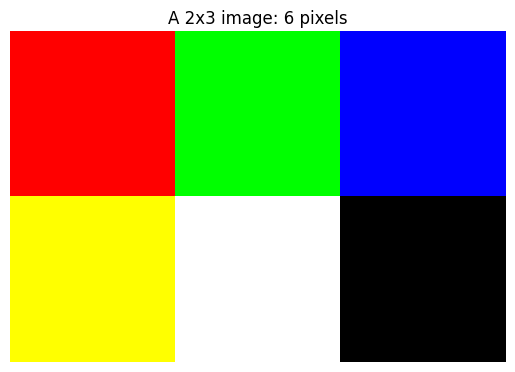

In [3]:
tiny = np.zeros((2, 3, 3), dtype=np.uint8)
tiny[0, 0] = [255, 0, 0]       # red
tiny[0, 1] = [0, 255, 0]       # green
tiny[0, 2] = [0, 0, 255]       # blue
tiny[1, 0] = [255, 255, 0]     # yellow
tiny[1, 1] = [255, 255, 255]   # white
tiny[1, 2] = [0, 0, 0]         # black

print("shape :", tiny.shape, " -> (height, width, channels)")
print("dtype :", tiny.dtype)
print("pixel [0,0] =", tiny[0, 0], "(pure red)")

plt.imshow(tiny, interpolation="nearest")
plt.title("A 2x3 image: 6 pixels")
plt.axis("off")
plt.show()

## 2. The 5 core steps

### Step 1 · Create a blank image and fill regions
- `np.zeros` → all zeros (black)
- `np.full` → every pixel set to a chosen colour
- `np.ones * 255` → white
- `np.random` → random noise

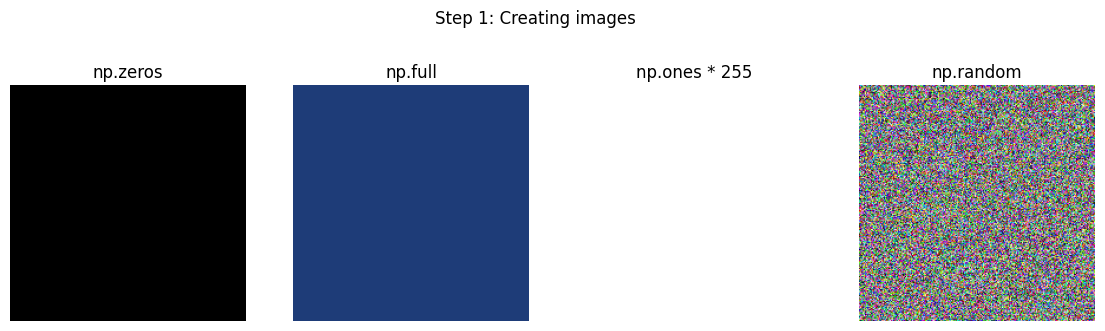

In [4]:
blank      = np.zeros((200, 200, 3), dtype=np.uint8)                 # black
background = np.full((200, 200, 3), [30, 60, 120], dtype=np.uint8)   # dark blue
white_patch = np.ones((200, 200, 3), dtype=np.uint8) * 255           # white
noise      = noise_image(200, 200, seed=42)                          # random pixels

fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, im, t in zip(ax, [blank, background, white_patch, noise],
                    ["np.zeros", "np.full", "np.ones * 255", "np.random"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.suptitle("Step 1: Creating images"); plt.show()

### Step 2 · Draw colour blocks and stripes with 3D slicing
Format: `img[rows, columns, channel]`. `start:stop` **includes start, excludes stop**.

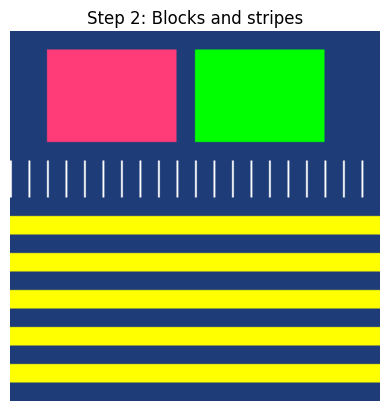

In [5]:
img = background.copy()                 # work on a copy

img[10:60, 20:90, 0] = 255              # slide example: only the RED channel of a block
img[10:60, 100:170] = [0, 255, 0]       # solid green block (all channels)

for r in range(100, 200, 20):           # horizontal yellow stripes
    img[r:r + 10, :] = [255, 255, 0]

img[70:90, ::10] = [255, 255, 255]      # step slicing: every 10th column -> thin vertical lines

plt.imshow(img); plt.title("Step 2: Blocks and stripes"); plt.axis("off"); plt.show()

### Step 3 · Crop, flip (negative-step slicing) and extract R/G/B channels
- `img[::-1]` reads rows from bottom to top → **upside down**
- `img[:, ::-1]` reads columns from right to left → **mirror**

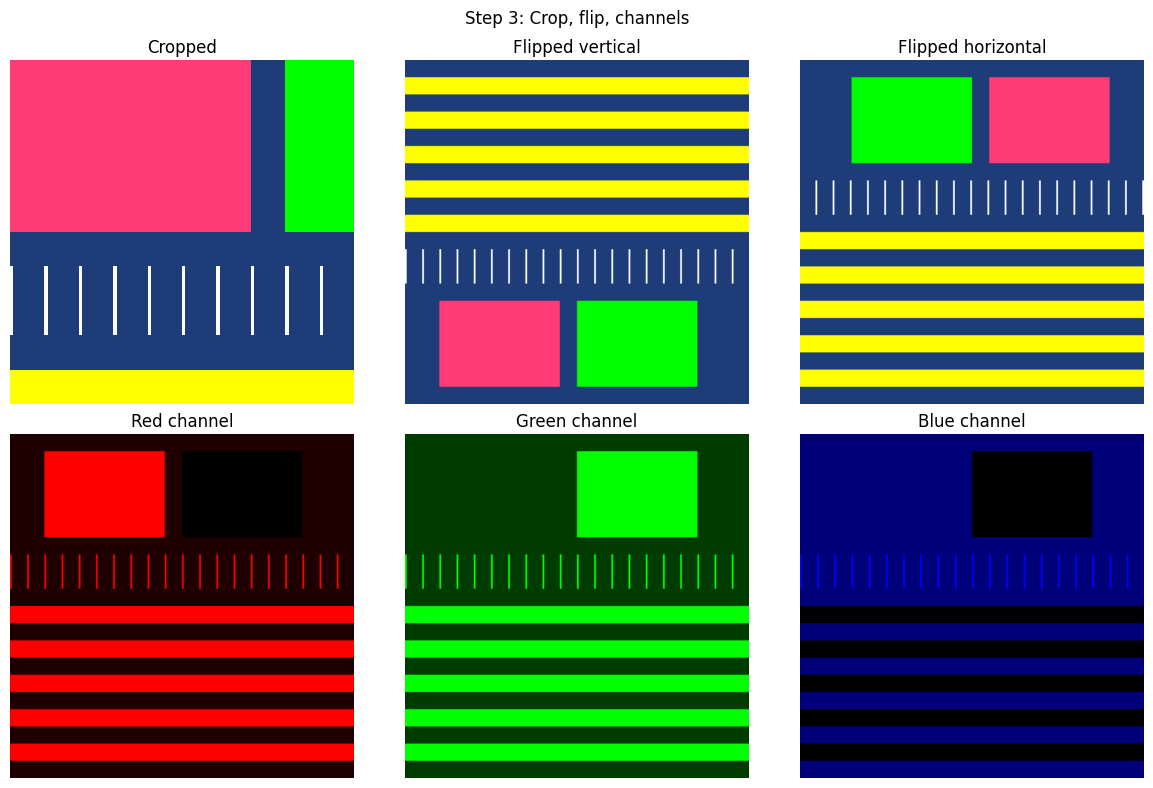

In [6]:
cropped = crop(img, 10, 20, 100, 100)
flipped_v = flip(img, "vertical")
flipped_h = flip(img, "horizontal")
red_only, green_only, blue_only = (get_channel(img, c) for c in range(3))

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
items = [(cropped, "Cropped"), (flipped_v, "Flipped vertical"), (flipped_h, "Flipped horizontal"),
         (red_only, "Red channel"), (green_only, "Green channel"), (blue_only, "Blue channel")]
for a, (im, t) in zip(ax.ravel(), items):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.suptitle("Step 3: Crop, flip, channels"); plt.tight_layout(); plt.show()

### Step 4 · Brighten / darken with `float32`, then use a boolean mask
`uint8` can't go above 255, so we convert to `float32`, multiply, **clip** to 0-255, and cast back to `uint8`. A **mask** is a True/False array used to pick pixels.

Bright pixels: 10400 out of 40000 (26.0%)


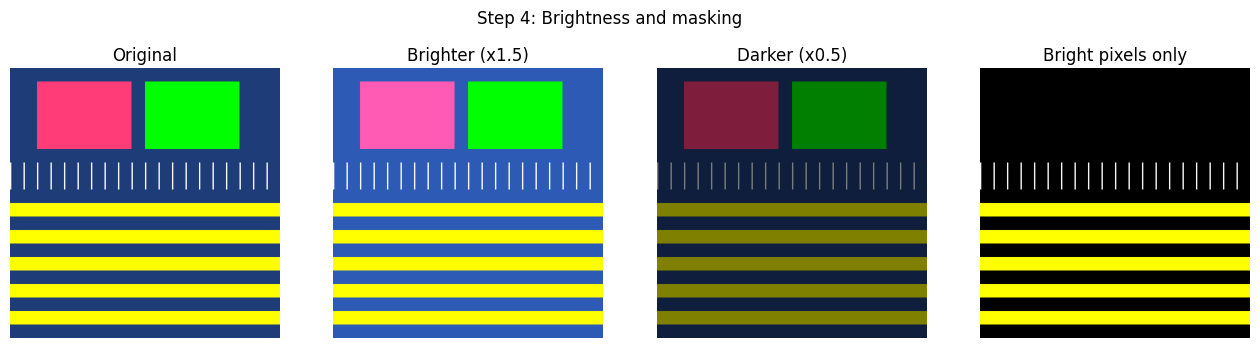

In [7]:
brighter = adjust_brightness(img, 1.5)
darker   = adjust_brightness(img, 0.5)

mask = bright_mask(img, threshold=150)      # True where the average of R,G,B > 150
print("Bright pixels:", mask.sum(), "out of", mask.size,
      f"({mask.mean() * 100:.1f}%)")
bright_only = keep_masked(img, mask)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, im, t in zip(ax, [img, brighter, darker, bright_only],
                    ["Original", "Brighter (x1.5)", "Darker (x0.5)", "Bright pixels only"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.suptitle("Step 4: Brightness and masking"); plt.show()

### Step 5 · Compare memory: `uint8` vs `float64`
`nbytes` = total bytes the array uses. 200 × 200 × 3 = 120,000 values. `uint8` = 1 byte each, `float64` = 8 bytes each.

uint8   :   120,000 bytes  (1x uint8)
float32 :   480,000 bytes  (4x uint8)
float64 :   960,000 bytes  (8x uint8)


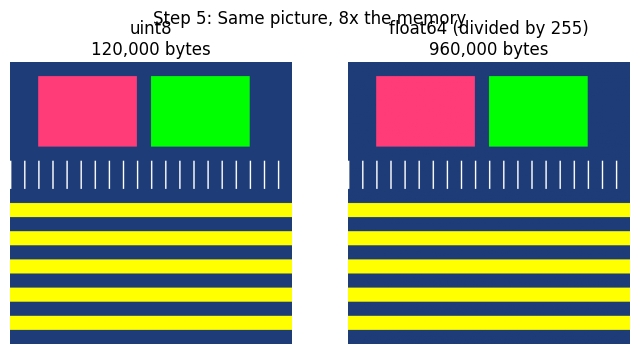

In [8]:
memory_report(img)

img_f64 = img.astype(np.float64)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img);            ax[0].set_title(f"uint8\n{img.nbytes:,} bytes")
ax[1].imshow(img_f64 / 255);  ax[1].set_title(f"float64 (divided by 255)\n{img_f64.nbytes:,} bytes")
for a in ax: a.axis("off")
plt.suptitle("Step 5: Same picture, 8x the memory"); plt.show()

**Takeaway:** the two images look identical, but `float64` costs 8× more memory. That's why images are stored as `uint8`. Note: `imshow` expects floats in the range 0-1, which is why we divided by 255.

## 3. Bonus: build a richer scene and apply filters
Now we use the toolkit to compose a nicer test image (gradient + shapes + checkerboard patch), then apply filters, all with plain NumPy.

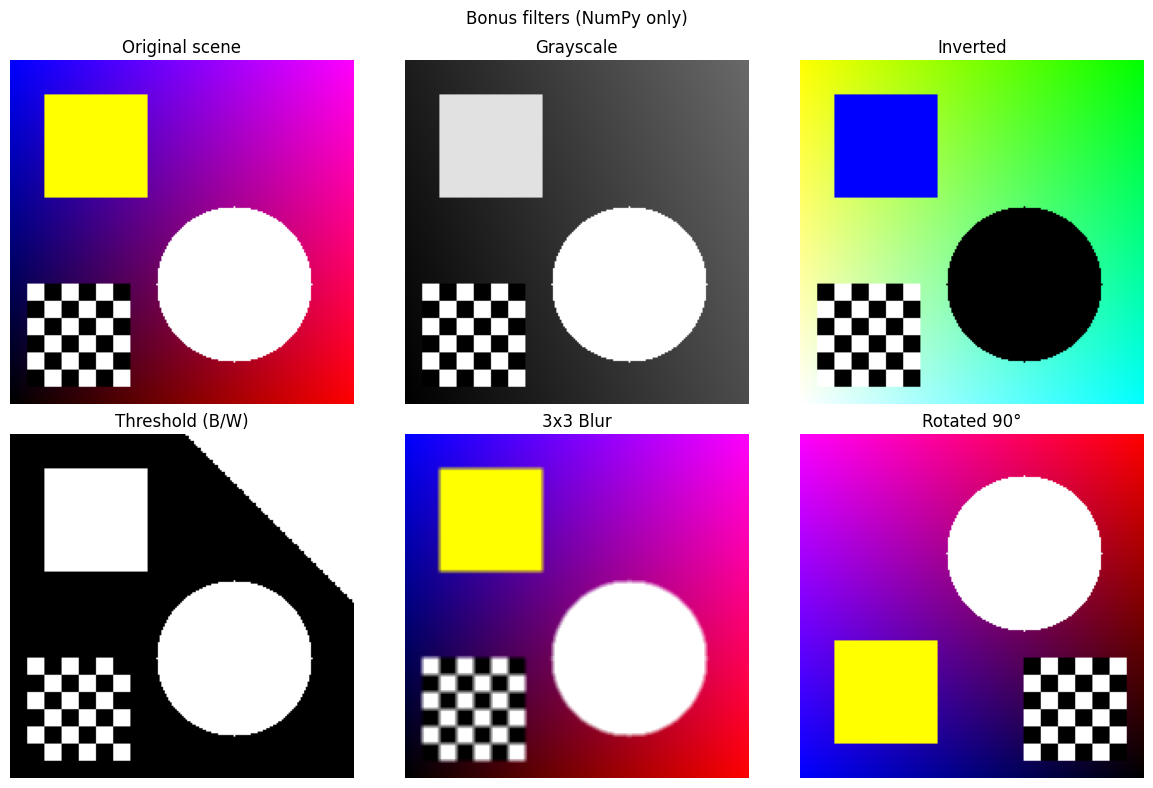

In [9]:
scene = gradient(200, 200)
scene = draw_rect(scene, 20, 20, 60, 60, (255, 255, 0))
scene = draw_circle(scene, 130, 130, 45, (255, 255, 255))
scene[130:190, 10:70] = checkerboard(200, 10)[:60, :60]   # checkerboard patch (good for seeing blur)

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
items = [(scene, "Original scene"), (grayscale(scene), "Grayscale"), (invert(scene), "Inverted"),
         (threshold(scene, 128), "Threshold (B/W)"), (box_blur(scene), "3x3 Blur"),
         (rotate90(scene), "Rotated 90°")]
for a, (im, t) in zip(ax.ravel(), items):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.suptitle("Bonus filters (NumPy only)"); plt.tight_layout(); plt.show()

## 4. The overflow bug (shown on purpose)
In `uint8`, `200 + 100` doesn't give 300. It **wraps around** to `44`. This is why Step 4 converts to `float32` first.

Wrong  (uint8 overflow)    : [44]
Right  (float32 then clip) : [255.]


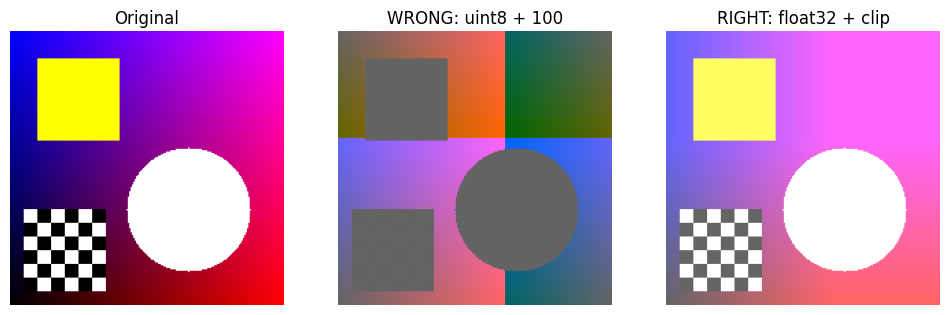

In [10]:
a = np.array([200], dtype=np.uint8)
print("Wrong  (uint8 overflow)    :", a + np.uint8(100))
print("Right  (float32 then clip) :", np.clip(a.astype(np.float32) + 100, 0, 255))

wrong = scene + np.uint8(100)                                   # wraps around -> glitchy colours
right = np.clip(scene.astype(np.float32) + 100, 0, 255).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a_, im, t in zip(ax, [scene, wrong, right],
                     ["Original", "WRONG: uint8 + 100", "RIGHT: float32 + clip"]):
    a_.imshow(im); a_.set_title(t); a_.axis("off")
plt.show()

## 5. Views vs copies
Slicing returns a **view** (same memory). Editing the slice edits the original. Use `.copy()` to get an independent array.

In [11]:
base = np.zeros((10, 10, 3), dtype=np.uint8)

view = base[0:5, 0:5]
view[:] = 255
print("After editing the VIEW, base[0,0] =", base[0, 0], "(original changed!)")

base2 = np.zeros((10, 10, 3), dtype=np.uint8)
safe = base2[0:5, 0:5].copy()
safe[:] = 255
print("After editing the COPY, base2[0,0] =", base2[0, 0], "(original safe)")
print("np.shares_memory(base, view):", np.shares_memory(base, view))

After editing the VIEW, base[0,0] = [255 255 255] (original changed!)
After editing the COPY, base2[0,0] = [0 0 0] (original safe)
np.shares_memory(base, view): True


## 6. Tests
A few `assert` checks prove the toolkit behaves correctly.

In [12]:
t = create_image(50, 50, (10, 20, 30))
assert t.shape == (50, 50, 3) and t.dtype == np.uint8
assert np.array_equal(flip(flip(t)), t)                          # flip twice = original
assert np.array_equal(flip(flip(t, "vertical"), "vertical"), t)
assert adjust_brightness(t, 100).max() == 255                    # no overflow
assert adjust_brightness(t, 0).max() == 0                        # fully dark
assert t.astype(np.float64).nbytes == 8 * t.nbytes               # 8x memory
assert crop(t, 5, 5, 20, 30).shape == (20, 30, 3)
assert get_channel(t, 0)[:, :, 1:].sum() == 0                    # only red kept
assert np.array_equal(invert(invert(t)), t)
assert box_blur(t).shape == t.shape
assert bright_mask(create_image(5, 5, (200, 200, 200))).all()
print("All tests passed ✅")

All tests passed ✅


## 7. Final overview image
One grid showing the main operations. This is also saved to `outputs/overview.png` for the README.

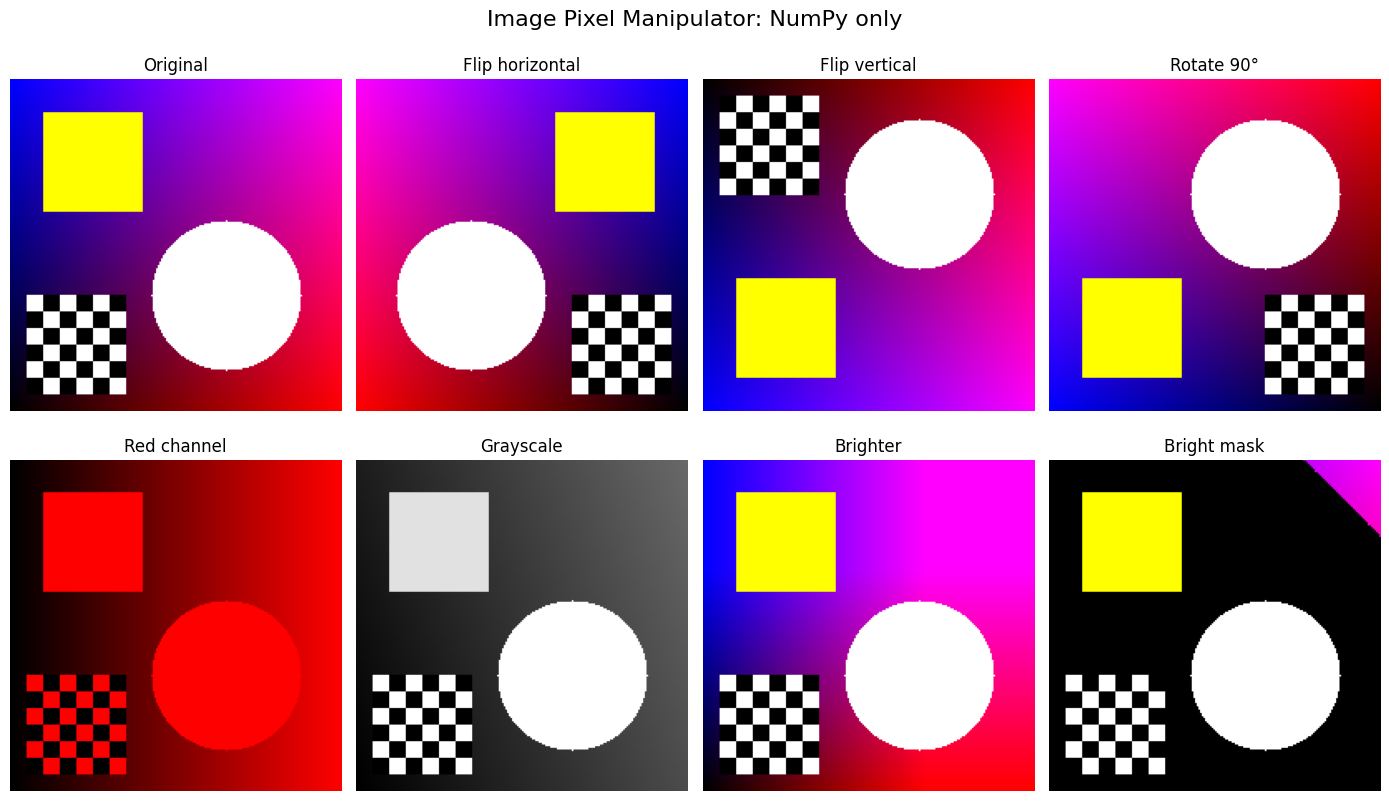

In [13]:
import os
os.makedirs("outputs", exist_ok=True)

panels = [
    (scene, "Original"), (flip(scene, "horizontal"), "Flip horizontal"),
    (flip(scene, "vertical"), "Flip vertical"), (rotate90(scene), "Rotate 90°"),
    (get_channel(scene, 0), "Red channel"), (grayscale(scene), "Grayscale"),
    (adjust_brightness(scene, 1.5), "Brighter"), (keep_masked(scene, bright_mask(scene, 150)), "Bright mask"),
]
fig, ax = plt.subplots(2, 4, figsize=(14, 8.5))
for a, (im, t) in zip(ax.ravel(), panels):
    a.imshow(im); a.set_title(t, fontsize=12); a.axis("off")
fig.suptitle("Image Pixel Manipulator: NumPy only", fontsize=16)
plt.tight_layout()
fig.savefig("outputs/overview.png", dpi=150, bbox_inches="tight")
plt.show()